<a href="https://colab.research.google.com/github/samanthafaith00001-png/Personal-Finance-Analysis/blob/main/Personal_Finance_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [29]:
import pandas as pd

# Load complecated financial dataset
df = pd.read_csv("cleaned_transactions.csv")

income = df[df["Type"] == "Income"]
expenses = df[df["Type"] == "Expense"]

total_income = income["Amount"].sum()
total_expenses = expenses["Amount"].sum()

balance = total_income - total_expenses

savings_rate = (
    (balance / total_income) * 100
    if total_income > 0 else 0
)

# Create dashboard
print("\n")
print("=" * 55)
print("          PERSONAL FINANCE DASHBOARD")
print("=" * 55)

print(f"Total Transactions: {len(df)}")

print(f"\Total Income:    KES {total_income:,.2f}")
print(f"\Total Expenses:  KES {total_expenses:,.2f}")

print("-" * 55)

print(f"Net Balance:      KES {balance:,.2f}")
print(f"Savings Rate:     {savings_rate:.2f}%")

print("-" * 55)

print("\nTOP FIVE EXPENSE CATEGORIES")

top_expenses = expenses.groupby(
    "Category"
)["Amount"].sum().sort_values(
    ascending=False
).head(5)

print(top_expenses)

print("\nFANANCIAL STATUS")

if balance > 0:
    print("Positive balance: Income exceeds expenses.")
elif balance < 0:
    print("Negative balance: Expenses exxceed income.")
else:
    print("Break-even: Icome equals expenses")

# Export dashboard report
with open("financial_dashboard.txt", "w") as file:

     file.write("PERSONAL FINANCE DASHBOARD\n")
     file.write("=" * 40 + "\n")

     file.write(f"Transactions: {len(df)}\n")
     file.write(f"Income: KES {total_income:,.2f}\n")
     file.write(f"Expenses: KES {total_expenses:,.2f}\n")
     file.write(f"Balance: KES {balance:,.2f}\n")
     file.write(f"Savings Rate: {savings_rate:,.2f}\n")

     file.write("\nTOP EXPENSE CATEGORIES\n")
     file.write(top_expenses.to_string())

print("\nDashboard report exported successfully!")
print("Project completed!")



          PERSONAL FINANCE DASHBOARD
Total Transactions: 300
\Total Income:    KES 0.00
\Total Expenses:  KES 1,614,551.04
-------------------------------------------------------
Net Balance:      KES -1,614,551.04
Savings Rate:     0.00%
-------------------------------------------------------

TOP FIVE EXPENSE CATEGORIES
Category
Utilities        255189.65
Food             214899.72
Entertainment    213389.97
Shopping         199847.23
Rent             197339.32
Name: Amount, dtype: float64

FANANCIAL STATUS
Negative balance: Expenses exxceed income.

Dashboard report exported successfully!
Project completed!


<>:27: SyntaxWarning: invalid escape sequence '\T'
<>:28: SyntaxWarning: invalid escape sequence '\T'
<>:27: SyntaxWarning: invalid escape sequence '\T'
<>:28: SyntaxWarning: invalid escape sequence '\T'
/tmp/ipykernel_437/2087416185.py:27: SyntaxWarning: invalid escape sequence '\T'
  print(f"\Total Income:    KES {total_income:,.2f}")
/tmp/ipykernel_437/2087416185.py:28: SyntaxWarning: invalid escape sequence '\T'
  print(f"\Total Expenses:  KES {total_expenses:,.2f}")


In [25]:
import pandas as pd
import numpy as np

np.random.seed(42)

categories = [
    "Salary", "Business", "Freelance",
    "Food", "Transport", "rent",
    "Shopping", "Entertainment",
    "Healthcare", "Utilities", "Education"
]
description = {
    "Salary", "Monthly salary",
    "Business", "Business revene",
    "Freelance", "Freelance payment",
    "Food", "Food and groceries",
    "Transport", "Transport expenses",
    "Rent", "Monthly rent",
    "Shopping", "Shopping expenses",
    "Entertainment", "Entertainment expenses",
    "Healthcare", "Healthcare expenses",
    "Utilities", "Utilities expenses",
    "Education", "Education expenses"
}

income_categories = [
    "Salary", "Business", "Freelance"
]
expense_categories = [
    "Food",
    "Transport",
    "Rent",
    "Shopping",
    "Entertainment",
    "Healthcare",
    "Utilities",
    "Education"
]

records = []

for i in range(300):
    transaction_type = np.random.choice(
        ["income", "Expense"],
        p=[0.30, 0.70]
    )

    if transaction_type =="Income":
        category = np.random.choice(income_categories)
        amount = round(np.random.uniform(5000, 100000), 2)
    else:
        category = np.random.choice(expense_categories)
        amount = round(np.random.uniform(100, 15000), 2)

    date = pd.Timestamp("2026-01-01") + pd.Timedelta(
        days=int(np.random.randint(0, 300))
    )

    records.append({
        "Transactions_ID": f"TXN{i+1:03}",
         "Date": date,
         "Type": transaction_type,
         "Category": category,
         "Amount": amount,
         "Payment_Method": np.random.choice(
             ["Cash", "M-Pesa", "Bank Transfer", "Card"]

         )
    })

df = pd.DataFrame(records)

df.to_csv("transactions.csv", index=False)

print("Financial dataset created successfully!")
print("Total transactions:", len(df))
print(df.head(10))


Financial dataset created successfully!
Total transactions: 300
  Transactions_ID       Date     Type       Category    Amount Payment_Method
0          TXN001 2026-03-13  Expense  Entertainment   2833.18           Cash
1          TXN002 2026-03-29  Expense      Transport   2424.32           Cash
2          TXN003 2026-09-15  Expense      Education   9798.24           Card
3          TXN004 2026-10-04  Expense     Healthcare    111.60           Cash
4          TXN005 2026-02-18  Expense     Healthcare    205.29  Bank Transfer
5          TXN006 2026-07-07  Expense      Transport    795.32           Card
6          TXN007 2026-02-20   income     Healthcare  11799.12           Card
7          TXN008 2026-05-15  Expense      Education   7054.77           Cash
8          TXN009 2026-01-14  Expense      Transport  14238.39         M-Pesa
9          TXN010 2026-04-02  Expense      Transport   1555.31  Bank Transfer


In [26]:
import pandas as pd
import numpy as np

df = pd.read_csv("transactions.csv")

# Convert dates into daytime format
df["Date"] = pd.to_datetime(df["Date"])

# Inspect the dataset
print("\nDATASET INFORMATION")
print(df.info())

# Check missing information
print("\nMISSING VALUES")
print(df.isnull().sum())

# Check duplicated records
print("\nDUBLICATE RECORDS")
print(df.duplicated().sum())

# Remove duplicates
df = df.drop_duplicates()

# Remove invalid transactions
df =df[df["Amount"] > 0]

# Standardize category names
df["Category"] = df["Category"].str.strip().str.title()

# Extract month and year
df["Month"] = df["Date"].dt.month
df["Year"] = df["Date"].dt.year
df["Month_Name"] = df["Date"].dt.strftime("%B")

# Create a clean CSV
df.to_csv("cleaned_transactions.csv", index=False)

print("\nCLEANING COMPLETED")
print("Remaining transactions:", len(df))
print(df.head(10))



DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   Transactions_ID  300 non-null    object        
 1   Date             300 non-null    datetime64[ns]
 2   Type             300 non-null    object        
 3   Category         300 non-null    object        
 4   Amount           300 non-null    float64       
 5   Payment_Method   300 non-null    object        
dtypes: datetime64[ns](1), float64(1), object(4)
memory usage: 14.2+ KB
None

MISSING VALUES
Transactions_ID    0
Date               0
Type               0
Category           0
Amount             0
Payment_Method     0
dtype: int64

DUBLICATE RECORDS
0

CLEANING COMPLETED
Remaining transactions: 300
  Transactions_ID       Date     Type       Category    Amount Payment_Method  \
0          TXN001 2026-03-13  Expense  Entertainment   2833.18       

In [27]:
import pandas as pd
import numpy as np

df = pd.read_csv("transactions.csv")

df["Date"] = pd.to_datetime(df["Date"])

# DATA CLEANING
df = df.drop_duplicates()
df = df.dropna(subset=["Date", "Type", "Category", "Amount"])
df = df[df["Amount"] > 0]

df["Month"] = df["Date"].dt.month
df["Year"] = df["Date"].dt.year
df["Month_Name"] = df["Date"].dt.strftime("%B")

df.to_csv("cleaned_transactions.csv", index=False)

# SEPARATE INCOME AND EXPENSES
income = df[df["Type"] == "Income"]
expenses = df[df["Type"] == "Expense"]
print(df["Type"].value_counts())

total_income = income["Amount"].sum()
total_expenses = expenses["Amount"].sum()

# FINANCIAL METRICS
net_profit = total_income - total_expenses

if total_income > 0:
  savings_rate = (net_profit / total_income)
else:
  savings_rate = 0

average_income = income["Amount"].mean()
average_expense = expenses["Amount"].mean()

# CATEGORY ANALYSIS
category_spending = expenses.groupby(
    "Category"
)["Amount"].sum().sort_values(ascending=False)

# MONTHLY ANALYSIS
monthly_income = income.groupby("Month")["Amount"].sum()
monthly_expenses = expenses.groupby("Month")["Amount"].sum()

# TRANSACTION ANALYSIS
largest_expense = expenses.nlargest(5, "Amount")
largest_income = income.nlargest(5, "Amount")

# PAYMENT METHOD ANALYSIS
payment_analysis = (
    df.groupby("Payment_Method")["Amount"]
    .sum()
    .sort_values(ascending=False)
)

# DISPLAY RESULTS
print("\n==================FINANCIAL METRICS====================\n")

print(f"Total Income: KES {total_income:.2f}")
print(f"Total Expenses: KES {total_expenses:.2f}")
print(f"Net Balance: kes {net_profit:.2f}")
print(f"Savings Rate: {savings_rate:.2%}")

print(f"\nAverage Income: KES {average_income:.2f}")
print(f"Average Expense: KES {average_expense}")

print("\nEXPEMSES BY CATEGORY")
print(category_spending)

print("\nMONTHLY INCOME")
print(monthly_income)

print("\nMONTHLY EXPENSEs")
print(monthly_expenses)

print("\nLARGEST EXPENSES")
print(largest_expense)

print("\nLARGEST INCOME")
print(largest_income)

print("\nPAYMENT METHOD ANALYSIS")
print(payment_analysis)

print("\n===========================================================")

# SAVE REPORTS
category_spending.to_csv("category_report.csv")
payment_analysis.to_csv("payment_report.csv")

monthly_report = pd.DataFrame({
    "Income": monthly_income,
    "Expenses": monthly_expenses
}).fillna(0)

monthly_report["Net_Balance"] = (
    monthly_report["Income"] - monthly_report["Expenses"]
)

monthly_report.to_csv("monthly_report,csv")

print("\nALL financial reports saved suuccessfully!")


Type
Expense    225
income      75
Name: count, dtype: int64

==================FINANCIAL METRICS====================

Total Income: KES 0.00
Total Expenses: KES 1614551.04
Net Balance: kes -1614551.04
Savings Rate: 0.00%

Average Income: KES nan
Average Expense: KES 7175.7824

EXPEMSES BY CATEGORY
Category
Utilities        255189.65
Food             214899.72
Entertainment    213389.97
Shopping         199847.23
Rent             197339.32
Healthcare       191607.49
Transport        185178.58
Education        157099.08
Name: Amount, dtype: float64

MONTHLY INCOME
Series([], Name: Amount, dtype: float64)

MONTHLY EXPENSEs
Month
1     145459.00
2     168045.62
3     150232.34
4     158574.71
5     178955.38
6     162392.10
7     109352.82
8     217727.74
9     184284.23
10    139527.10
Name: Amount, dtype: float64

LARGEST EXPENSES
    Transactions_ID       Date     Type    Category    Amount Payment_Method  \
123          TXN124 2026-02-23  Expense   Utilities  14937.89         M-Pesa  

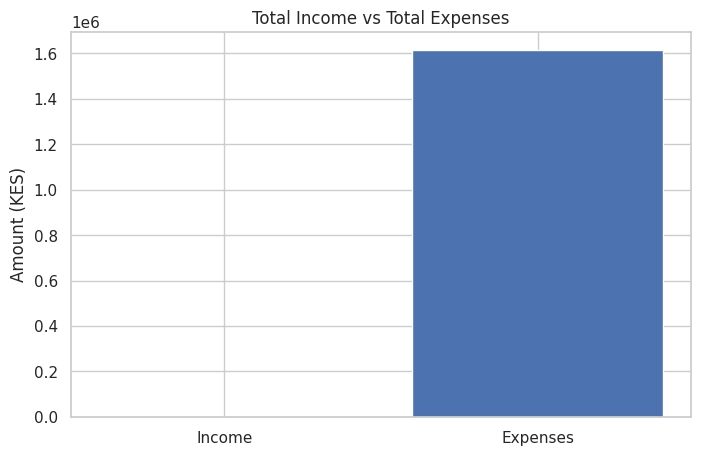

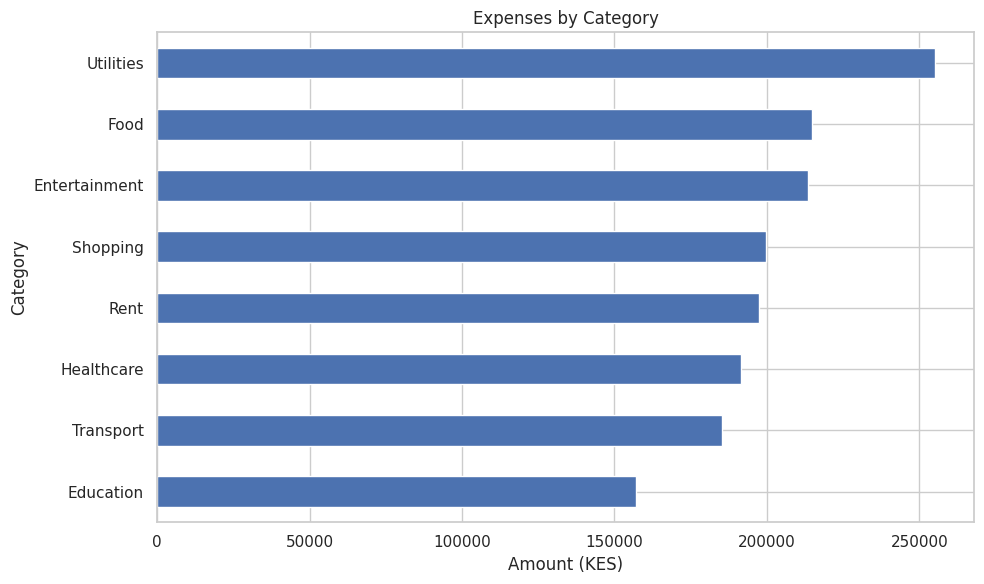

<Figure size 1000x500 with 0 Axes>

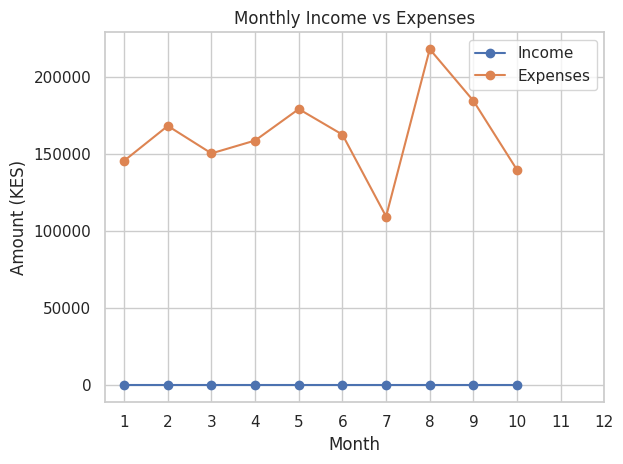

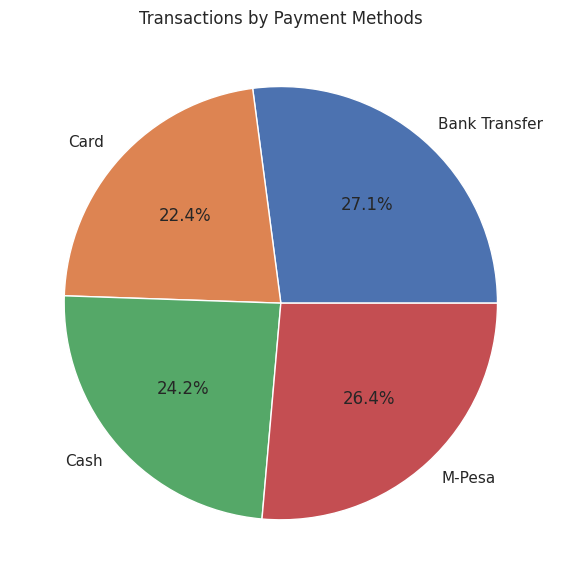

All four financial charts created successfully!


In [28]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("cleaned_transactions.csv")

sns.set_theme(style="whitegrid")

income = df[df["Type"] == "Income"]
expenses = df[df["Type"] == "Expense"]

# CHART 1: INCOME VS EXPENSES
income_total = income["Amount"].sum()
expenses_total = expenses["Amount"].sum()

plt.figure(figsize=(8, 5))

plt.bar(
    ["Income", "Expenses"],
    [income_total, expenses_total]
)

plt.title("Total Income vs Total Expenses")
plt.ylabel("Amount (KES)")
plt.savefig("income_vs_expenses.png")
plt.show()

# CHART 2: EXPENSES BY CATEGORY
category_data = expenses.groupby(
    "Category"
)["Amount"].sum().sort_values()

plt.figure(figsize=(10, 6))

category_data.plot(kind="barh")

plt.title("Expenses by Category")
plt.xlabel("Amount (KES)")
plt.ylabel("Category")
plt.tight_layout()
plt.savefig("expenses_by_category.png")
plt.show()

# CHART 3: MONTHLY FINANCIAL PERFORMANCE
income_monthly = income.groupby("Month")["Amount"].sum()
expenses_monthly = expenses.groupby("Month")["Amount"].sum()

monthly = pd.DataFrame({
    "Income": income_monthly,
    "Expenses": expenses_monthly
}).fillna(0)

plt.figure(figsize=(10, 5))

monthly.plot(kind="line", marker="o")

plt.title("Monthly Income vs Expenses")
plt.xlabel("Month")
plt.ylabel("Amount (KES)")
plt.xticks(range(1, 13))
plt.tight_layout()
plt.savefig("monthly_performance.png")
plt.show()

# CHAT 4: PAYMENT METHODS
payments_data = df.groupby(
    "Payment_Method"
)["Amount"].sum()

plt.figure(figsize=(8, 6))

payments_data.plot(
    kind="pie",
    autopct="%1.1f%%",
)

plt.title("Transactions by Payment Methods")
plt.ylabel("")
plt.tight_layout()
plt.savefig("payment_methods.png")
plt.show()

print("All four financial charts created successfully!")